[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C10/E10-1_Familles_Pieces_CORRIGE.ipynb)

# Familles de pièces : regrouper sans étiquette

## Le contexte

Un contrôle final mesure chaque pièce tournée : diamètre extérieur, longueur, diamètre de l'alésage (0 pour une pièce pleine), masse et rugosité. Le bureau des méthodes sait que la production se répartit en cinq familles, des axes, des bagues, des brides, des entretoises et des vis, mais le contrôle n'enregistre jamais la famille. Quelques pièces atypiques, hors famille, se glissent aussi dans les lots.

On voudrait retrouver les familles à partir des seules mesures, pour suivre chacune d'elles séparément. Aucune colonne ne donne la réponse à l'apprentissage : c'est un problème de regroupement (apprentissage non supervisé).

Défi : regrouper les 600 pièces à partir des cinq mesures, et obtenir un indice de Rand ajusté supérieur à celui du modèle de départ. Cet indice compare le regroupement trouvé à la famille de référence que le fabricant connaît : 1 pour un regroupement identique, 0 pour un regroupement sans lien avec elle. Le modèle de départ est un K-means à cinq groupes sur les mesures mises à l'échelle ; il atteint 0,7518 : à vous de faire mieux. La famille de référence ne sert qu'à noter, une seule fois, à la fin.

## Les données

Fichier `MecaIA-Familles_Pieces.xlsx`, dans le dossier `donnees` du dépôt : 600 pièces, 6 colonnes. Une ligne est une pièce usinée, mesurée au contrôle final.

| Colonne | Signification | Unité |
|---|---|---|
| `diametre_mm` | diamètre extérieur | mm |
| `longueur_mm` | longueur de la pièce | mm |
| `alesage_mm` | diamètre de l'alésage, 0 pour une pièce pleine | mm |
| `masse_g` | masse pesée | g |
| `rugosite_Ra_um` | rugosité Ra de la surface usinée (quelques cases vides) | µm |
| `famille_reference` | famille connue du fabricant, pour noter seulement | catégorie |

Origine : jeu simulé, dimensions et masses tirées pour cinq familles de pièces (loi de la masse d'un cylindre creux) et quelques pièces atypiques. La colonne `famille_reference` n'est jamais une entrée du modèle, et ce corrigé ne la lit qu'à la dernière cellule, pour calculer le score.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on désigne les mesures par exclusion de la colonne de référence : elle ne passe jamais dans l'apprentissage. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Familles_Pieces.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Familles_Pieces.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

colonne_cachee = "famille_reference"
mesures = [colonne for colonne in df.columns if colonne != colonne_cachee]
X = df[mesures]
print("dimensions des mesures :", X.shape)
print("cases vides par mesure :")
print(X.isna().sum().to_string())
print(X.describe().loc[["min", "50%", "max"]].round(1).T.to_string())

dimensions des mesures : (600, 5)
cases vides par mesure :
diametre_mm        0
longueur_mm        0
alesage_mm         0
masse_g            0
rugosite_Ra_um    16
                min    50%      max
diametre_mm     6.0   41.1    211.3
longueur_mm     6.5   42.0    329.6
alesage_mm      0.0   29.6     83.7
masse_g         1.4  317.6  43320.0
rugosite_Ra_um  0.2    1.5      5.9


Lecture du résultat : 600 pièces, 5 mesures. Seule la rugosité a des cases vides, 16 au total : il faudra les remplacer. Les ordres de grandeur sont très différents : la masse va de 1,4 à 43320 g, la rugosité de 0,2 à 5,9 µm. Une pièce pleine a un alésage nul : 246 pièces sont dans ce cas.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Familles_Pieces.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : pas de base de test

Un regroupement n'a pas de réponse à prédire : il s'apprend et se juge sur toutes les pièces. Il n'y a donc pas de découpage entre apprentissage et test ; la base de test du défi est le jeu entier, et le score se calcule une seule fois, à la dernière cellule, contre la famille de référence. Jusque-là, aucune cellule ne lit cette colonne.

### Étape 3 : regarder les pièces

Deux vues suffisent pour deviner la structure : le diamètre contre la longueur, et la masse (en échelle logarithmique) contre l'alésage. Les points sont tous gris : on ne sait pas encore quelle pièce est de quelle famille.

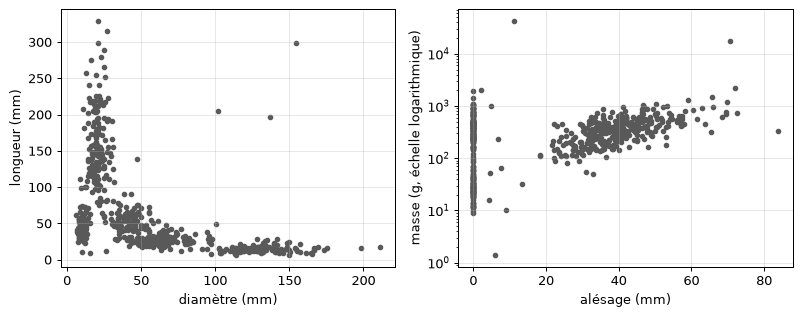

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(X["diametre_mm"], X["longueur_mm"], s=12, color="0.35")
axes[0].set_xlabel("diamètre (mm)")
axes[0].set_ylabel("longueur (mm)")
axes[1].scatter(X["alesage_mm"], X["masse_g"], s=12, color="0.35")
axes[1].set_yscale("log")
axes[1].set_xlabel("alésage (mm)")
axes[1].set_ylabel("masse (g, échelle logarithmique)")
for axe in axes:
    axe.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Lecture du résultat : les pièces ne forment pas un seul nuage. Dans la première vue, on devine des amas : des pièces longues et minces, des pièces larges et courtes. Dans la seconde, les pièces sans alésage se rangent sur la verticale de gauche. Les amas ont des tailles très différentes : le regroupement devra juger des distances entre des mesures qui n'ont pas la même unité.

### Étape 4 : peser le rôle de chaque mesure

Le K-means regroupe les points proches au sens de la distance usuelle. Une mesure à grande variance pèse donc davantage dans cette distance. On compare la part de la variance totale que porte chaque mesure brute.

In [3]:
part_variance = X.var() / X.var().sum()
print((100 * part_variance).round(2).to_string())

diametre_mm        0.06
longueur_mm        0.12
alesage_mm         0.01
masse_g           99.82
rugosite_Ra_um     0.00


Lecture du résultat : la masse porte 99,8 % de la variance totale, loin devant toutes les autres mesures. Un K-means sur les mesures brutes ne regarderait pratiquement que la masse. Il faut mettre les mesures à l'échelle, et remplacer les cases vides de la rugosité, avant de regrouper.

### Étape 5 : préparer les mesures et choisir le nombre de groupes

La préparation remplace les cases vides par la médiane de la colonne, puis centre et réduit chaque mesure. Le nombre de groupes se lit sans étiquette, sur deux courbes : l'inertie (somme des carrés des distances aux centres, qui baisse toujours) et la silhouette (qui mesure à quel point chaque pièce est plus proche de son groupe que du groupe voisin, et qui doit être grande).

2 groupes : inertie 1890, silhouette 0.435
3 groupes : inertie 1445, silhouette 0.504
4 groupes : inertie 929, silhouette 0.517
5 groupes : inertie 508, silhouette 0.596
6 groupes : inertie 414, silhouette 0.596
7 groupes : inertie 346, silhouette 0.541
8 groupes : inertie 283, silhouette 0.471


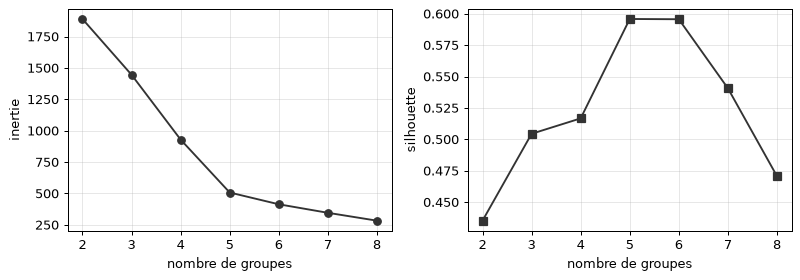

In [4]:
# Solution :
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

preprocessor = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
X_prep = preprocessor.fit_transform(X)
nombres = list(range(2, 9))
inerties, silhouettes = [], []
for k in nombres:
    km = KMeans(n_clusters=k, n_init=10, random_state=GRAINE).fit(X_prep)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_prep, km.labels_))
    print(f"{k} groupes : inertie {km.inertia_:.0f}, silhouette {silhouettes[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(nombres, inerties, "o-", color="0.2")
axes[0].set_ylabel("inertie")
axes[1].plot(nombres, silhouettes, "s-", color="0.2")
axes[1].set_ylabel("silhouette")
for axe in axes:
    axe.set_xlabel("nombre de groupes")
    axe.grid(alpha=0.3)
fig.tight_layout()
plt.show()
# Fin de la solution

Lecture du résultat : l'inertie baisse sans coude net, comme toujours. La silhouette est plus lisible : elle est maximale à 5 groupes (0,596) et reste à 0,596 pour 6, avant de baisser. Cela rejoint ce que sait le bureau des méthodes : on retient cinq groupes pour le modèle de départ.

### Étape 6 : construire le modèle de départ

Le modèle de départ est celui de la section du livre : un K-means à cinq groupes sur les mesures préparées. Le pipeline apprend la préparation et les centres sur les pièces ; `n_init=10` relance dix fois l'algorithme depuis des centres différents et garde le meilleur, la graine fixe le tirage.

In [5]:
# Solution :
model = make_pipeline(preprocessor, KMeans(n_clusters=5, n_init=10, random_state=GRAINE))
groupes = model.fit_predict(X)
effectifs = np.bincount(groupes)
print("effectif de chaque groupe :", effectifs.tolist())
# Fin de la solution

effectif de chaque groupe : [161, 229, 118, 90, 2]


Lecture du résultat : les effectifs sont très inégaux, de 2 à 229 pièces. Le plus petit groupe ne compte que 2 pièces, de masse moyenne 30600 g contre 318 g de médiane : le K-means lui a consacré un groupe entier pour des pièces extrêmes, au lieu de séparer deux familles voisines. La suite dira ce que ce choix coûte.

## Pour aller plus loin : changer de représentation et d'algorithme

Le modèle de départ de l'étape 6 reste le score de référence du défi. La cellule suivante construit des regroupements concurrents, toujours sans la famille de référence : K-means sur les mesures brutes, sur les logarithmes des mesures réduits, classification hiérarchique de Ward, mélange gaussien et DBSCAN. Pour le mélange gaussien, le nombre de composantes se lit sur le critère d'information bayésien (BIC), le plus bas désignant le meilleur compromis. Les scores contre la famille de référence se lisent à la dernière cellule, une fois.

In [6]:
# Solution :
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture

X_plein = X.fillna(X.median())
Z = StandardScaler().fit_transform(np.log1p(X_plein))       # logarithmes, puis mise à l'échelle
bic = {k: GaussianMixture(n_components=k, n_init=5, random_state=GRAINE).fit(Z).bic(Z) for k in range(2, 10)}
k_bic = min(bic, key=bic.get)
print("BIC le plus bas pour", k_bic, "composantes")
candidats = {
    "K-means, mesures brutes": KMeans(n_clusters=5, n_init=10, random_state=GRAINE).fit_predict(X_plein),
    "K-means, mesures réduites (modèle de départ)": groupes,
    "K-means, logarithmes réduits": KMeans(n_clusters=5, n_init=10, random_state=GRAINE).fit_predict(Z),
    "hiérarchique de Ward, logarithmes": AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(Z),
    f"mélange gaussien à {k_bic} composantes, logarithmes":
        GaussianMixture(n_components=k_bic, n_init=5, random_state=GRAINE).fit_predict(Z),
    "DBSCAN, logarithmes": DBSCAN(eps=0.5, min_samples=5).fit_predict(Z)}
for nom, g in candidats.items():
    print(f"{nom} : {len(set(g) - {-1})} groupes, {int((g == -1).sum())} points isolés")
# Fin de la solution

BIC le plus bas pour 6 composantes
K-means, mesures brutes : 5 groupes, 0 points isolés
K-means, mesures réduites (modèle de départ) : 5 groupes, 0 points isolés
K-means, logarithmes réduits : 5 groupes, 0 points isolés
hiérarchique de Ward, logarithmes : 5 groupes, 0 points isolés
mélange gaussien à 6 composantes, logarithmes : 6 groupes, 0 points isolés
DBSCAN, logarithmes : 5 groupes, 35 points isolés


## Le score de référence

Le score publié est l'indice de Rand ajusté du modèle de départ de l'étape 6, calculé sur toutes les pièces contre la famille de référence. Un témoin sans apprentissage donne le point de comparaison le plus bas : cinq tranches de masse de même effectif. L'empreinte identifie la base de test, ici toutes les pièces.

In [7]:
import hashlib

from sklearn.metrics import adjusted_rand_score

reference = df[colonne_cachee]
score = adjusted_rand_score(reference, groupes)
score_temoin = adjusted_rand_score(reference, pd.qcut(X["masse_g"], 5, labels=False))
positions = ",".join(str(i) for i in sorted(df.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print(f"témoin sans apprentissage, cinq tranches de masse : {score_temoin:.4f}")
print("SCORE_REFERENCE rand_ajuste = %.4f" % score)
# Solution :
ari_candidats = {nom: adjusted_rand_score(reference, g) for nom, g in candidats.items()}
for nom, valeur in ari_candidats.items():
    print(f"{nom} : indice de Rand ajusté {valeur:.4f}")
# Fin de la solution

EMPREINTE_TEST = 439f3a6b5500d0c863fc6e848e7c568e10ce32f71c6dab87f01cb9a35602ccfb
témoin sans apprentissage, cinq tranches de masse : 0.1724
SCORE_REFERENCE rand_ajuste = 0.7518
K-means, mesures brutes : indice de Rand ajusté 0.0968
K-means, mesures réduites (modèle de départ) : indice de Rand ajusté 0.7518
K-means, logarithmes réduits : indice de Rand ajusté 0.8466
hiérarchique de Ward, logarithmes : indice de Rand ajusté 0.9012
mélange gaussien à 6 composantes, logarithmes : indice de Rand ajusté 0.9712
DBSCAN, logarithmes : indice de Rand ajusté 0.7775


## Synthèse

1. Un regroupement ne se juge pas sur lui-même : la famille de référence, cachée jusqu'à la fin, sert à noter. Le modèle de départ atteint 0,7518, contre 0,1724 pour le témoin sans apprentissage (cinq tranches de masse).
2. Les distances mélangent des mesures de natures différentes : sans mise à l'échelle, le K-means ne voit que la masse et tombe à 0,0968.
3. Les mesures de taille suivent des lois log-normales : passer aux logarithmes avant de réduire fait monter le K-means à 0,8466.
4. Le nombre de composantes d'un mélange gaussien se lit sur le BIC, sans étiquette : il désigne 6 composantes, soit les cinq familles de l'atelier et un sixième groupe, et l'indice monte à 0,9712.
5. DBSCAN écarte 35 points comme du bruit et exige de régler son rayon : il atteint 0,7775 avec un rayon de 0,5, sans nombre de groupes à fixer.